In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [7]:
df=pd.read_csv("drug200.csv")

In [8]:
data=df.copy()
data.head()


,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,drugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,drugY


In [10]:

X = data[["Age","Na_to_K"]].to_numpy(dtype=float)

# Scale the features
mean = X.mean(axis=0)
std = X.std(axis=0)
X = (X - mean) / std

print(X)

[[-1.29159102  1.28652212]
 [ 0.16269866 -0.4151454 ]
 [ 0.16269866 -0.82855818]
 [-0.988614   -1.14996267]
 [ 1.0110343   0.27179427]
 [-1.35218642 -1.03769314]
 [ 0.28388946  0.02643885]
 [-0.20087376 -0.70046821]
 [ 0.9504389  -0.12676951]
 [-0.07968296  0.45567206]
 [ 0.16269866 -0.59916196]
 [-0.62504158  0.43221897]
 [-0.07968296 -0.09832049]
 [ 1.79877454  0.674105  ]
 [ 0.34448487 -0.46926791]
 [-1.71575884 -0.0788919 ]
 [ 1.49579753 -0.64245998]
 [-0.07968296 -0.29316156]
 [-1.29159102 -1.21935052]
 [-0.74623239  1.37242427]
 [ 0.76865269  0.42236589]
 [ 1.13222511  1.36451406]
 [ 0.16269866  2.00995979]
 [ 0.22329406 -0.14550423]
 [-0.68563699  2.41490725]
 [-0.988614    0.37809645]
 [-0.80682779  1.9819271 ]
 [ 0.28388946 -0.93028076]
 [-0.32206457  0.91765633]
 [ 0.04150785  0.25902691]
 [-1.59456803 -1.01784822]
 [ 1.79877454 -0.90446848]
 [ 0.28388946 -0.70366006]
 [ 1.25341591  2.19147839]
 [ 0.52627108 -0.27081868]
 [ 0.10210325 -1.2211546 ]
 [-0.74623239 -0.92139911]
 

In [11]:
K = 3

np.random.seed(42)

indices = np.random.choice(len(X), K, replace=False)

centroids = X[indices]

print("Initial centroids:")
print(centroids)


Initial centroids:
[[-0.50385078 -0.64676202]
 [-1.71575884 -0.0788919 ]
 [-1.59456803 -1.01784822]]


In [12]:
distances = np.zeros((len(X), K))

for i in range(K):
    distances[:, i] = np.sqrt(
        np.sum((X - centroids[i]) ** 2, axis=1)
    )

labels = np.argmin(distances, axis=1)

print(labels)

[1 0 0 2 0 2 0 0 0 0 0 0 0 0 0 1 0 0 2 1 0 0 0 0 1 1 1 0 0 0 2 0 0 0 0 0 0
 0 0 2 0 0 0 2 0 0 0 0 1 1 0 0 0 1 0 1 0 1 0 0 1 2 0 0 0 0 0 2 0 1 0 1 2 0
 0 1 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 1 1 0 0 0 0 1 0 2 0 0 1 0
 0 0 0 2 0 0 0 0 0 1 1 1 0 0 1 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 2 0 0 0 0 0 0 0 1 0 0 1 0 2 0 1
 0 0 0 0 0 0 2 0 0 1 0 2 0 1 0]


In [13]:
new_centroids = np.zeros((K, X.shape[1]))

for i in range(K):
    points = X[labels == i]

    if len(points) > 0:
        new_centroids[i] = points.mean(axis=0)
    else:
        new_centroids[i] = centroids[i]

centroids = new_centroids

print("Updated centroids:")
print(centroids)

Updated centroids:
[[ 0.41736312 -0.18089578]
 [-1.08960634  1.13029924]
 [-1.40899461 -0.86988731]]


In [14]:
K = 3
np.random.seed(42)

centroids = X[
    np.random.choice(len(X), K, replace=False)
].copy()

for iteration in range(100):

    # Assign points to nearest centroid
    distances = np.zeros((len(X), K))

    for i in range(K):
        distances[:, i] = np.sqrt(
            np.sum((X - centroids[i]) ** 2, axis=1)
        )

    labels = np.argmin(distances, axis=1)

    # Calculate new centroids
    new_centroids = centroids.copy()

    for i in range(K):
        points = X[labels == i]

        if len(points) > 0:
            new_centroids[i] = points.mean(axis=0)

    # Check whether centroids have stopped moving
    if np.allclose(centroids, new_centroids):
        print("Converged after", iteration + 1, "iterations")
        centroids = new_centroids
        break

    centroids = new_centroids

print("Final cluster labels:", labels)

Converged after 6 iterations
Final cluster labels: [1 0 0 2 0 2 0 2 0 1 0 2 2 0 0 2 0 2 2 1 0 1 1 0 1 2 1 0 1 0 2 0 0 1 0 0 2
 2 2 2 0 0 0 2 0 0 2 0 1 2 0 0 1 2 0 2 0 1 0 2 1 2 0 0 0 1 2 2 1 1 0 2 2 1
 2 2 2 2 2 2 0 0 2 2 0 0 0 0 1 0 0 2 1 1 0 2 1 1 1 2 2 0 2 0 1 2 2 1 0 2 0
 0 2 0 2 0 0 2 2 1 1 2 1 2 0 1 0 2 1 2 0 1 0 1 1 0 0 2 0 0 0 1 0 0 2 0 2 2
 0 2 0 0 0 0 2 0 2 1 0 2 2 0 2 1 2 2 1 0 1 2 2 0 2 2 2 0 0 2 2 0 1 0 2 2 1
 1 0 0 1 0 0 2 0 0 1 0 2 0 2 2]


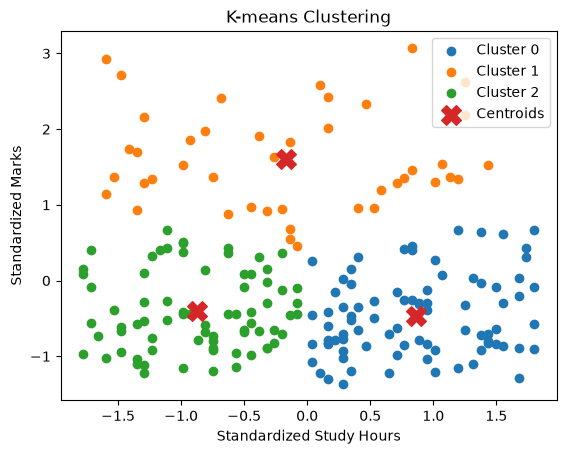

In [15]:
for i in range(K):
    points = X[labels == i]

    plt.scatter(
        points[:, 0],
        points[:, 1],
        label=f"Cluster {i}"
    )

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker="X",
    s=200,
    label="Centroids"
)

plt.xlabel("Standardized Study Hours")
plt.ylabel("Standardized Marks")
plt.title("K-means Clustering")
plt.legend()
plt.show()

# Decision Trees


In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data = pd.read_csv("penguins.csv")

features = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

target = "species"

# Keep only the columns we need
data = data[features + [target]]

# Remove rows with missing values in these columns
data = data.dropna()

X = data[features]
y = data[target]

print(data.head())
print("Number of usable rows:", len(data))
print(y.value_counts())

   bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g species
0            39.1           18.7              181.0       3750.0  Adelie
1            39.5           17.4              186.0       3800.0  Adelie
2            40.3           18.0              195.0       3250.0  Adelie
4            36.7           19.3              193.0       3450.0  Adelie
5            39.3           20.6              190.0       3650.0  Adelie
Number of usable rows: 342
species
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64


In [27]:
np.random.seed(42)

indices = np.random.permutation(len(X))

split_point = int(0.8 * len(X))

train_indices = indices[:split_point]
test_indices = indices[split_point:]

X_train = X.iloc[train_indices]
X_test = X.iloc[test_indices]

y_train = y.iloc[train_indices]
y_test = y.iloc[test_indices]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 273
Testing rows: 69


In [28]:
def gini(y):
    probabilities = y.value_counts(normalize=True)
    return 1 - np.sum(probabilities ** 2)

In [29]:
def best_split(X, y):
    best_feature = None
    best_threshold = None
    best_impurity = float("inf")

    for feature in X.columns:
        values = np.sort(X[feature].unique())

        # Test points halfway between consecutive values
        thresholds = (values[:-1] + values[1:]) / 2

        for threshold in thresholds:
            left = X[feature] <= threshold
            right = X[feature] > threshold

            y_left = y[left]
            y_right = y[right]

            if len(y_left) == 0 or len(y_right) == 0:
                continue

            weighted_gini = (
                len(y_left) / len(y) * gini(y_left)
                + len(y_right) / len(y) * gini(y_right)
            )

            if weighted_gini < best_impurity:
                best_impurity = weighted_gini
                best_feature = feature
                best_threshold = threshold

    return best_feature, best_threshold, best_impurity

In [30]:
feature, threshold, impurity = best_split(X_train, y_train)

print("Best feature:", feature)
print("Best threshold:", threshold)
print("Weighted Gini:", impurity)

Best feature: flipper_length_mm
Best threshold: 206.5
Weighted Gini: 0.30871319402247244


In [31]:
def build_tree(X, y, depth=0, max_depth=4, min_samples=4):

    # Stop if all penguins belong to one species
    if len(y.unique()) == 1:
        return {"prediction": y.iloc[0]}

    # Stop if the tree is deep enough
    if depth >= max_depth:
        return {"prediction": y.mode().iloc[0]}

    # Stop if the group is too small
    if len(y) < min_samples:
        return {"prediction": y.mode().iloc[0]}

    feature, threshold, impurity = best_split(X, y)

    if feature is None:
        return {"prediction": y.mode().iloc[0]}

    left = X[feature] <= threshold
    right = X[feature] > threshold

    # Avoid creating very small branches
    if left.sum() < min_samples or right.sum() < min_samples:
        return {"prediction": y.mode().iloc[0]}

    return {
        "feature": feature,
        "threshold": threshold,
        "left": build_tree(
            X[left], y[left], depth + 1, max_depth, min_samples
        ),
        "right": build_tree(
            X[right], y[right], depth + 1, max_depth, min_samples
        )
    }


tree = build_tree(X_train, y_train)

print(tree)

{'feature': 'flipper_length_mm', 'threshold': np.float64(206.5), 'left': {'feature': 'bill_length_mm', 'threshold': np.float64(43.35), 'left': {'feature': 'bill_length_mm', 'threshold': np.float64(42.3), 'left': {'feature': 'bill_depth_mm', 'threshold': np.float64(16.65), 'left': {'prediction': 'Adelie'}, 'right': {'prediction': 'Adelie'}}, 'right': {'prediction': 'Adelie'}}, 'right': {'feature': 'body_mass_g', 'threshold': np.float64(4125.0), 'left': {'prediction': 'Chinstrap'}, 'right': {'feature': 'bill_length_mm', 'threshold': np.float64(49.599999999999994), 'left': {'prediction': 'Adelie'}, 'right': {'prediction': 'Chinstrap'}}}}, 'right': {'feature': 'bill_depth_mm', 'threshold': np.float64(17.55), 'left': {'prediction': 'Gentoo'}, 'right': {'prediction': 'Chinstrap'}}}


In [32]:
def predict_one(tree, sample):

    # If we reach a leaf, return its prediction
    if "prediction" in tree:
        return tree["prediction"]

    feature = tree["feature"]
    threshold = tree["threshold"]

    if sample[feature] <= threshold:
        return predict_one(tree["left"], sample)
    else:
        return predict_one(tree["right"], sample)

In [33]:
sample = X_test.iloc[0]

prediction = predict_one(tree, sample)

print("Measurements:")
print(sample)

print("\nActual species:", y_test.iloc[0])
print("Predicted species:", prediction)

Measurements:
bill_length_mm         50.6
bill_depth_mm          19.4
flipper_length_mm     193.0
body_mass_g          3800.0
Name: 299, dtype: float64

Actual species: Chinstrap
Predicted species: Chinstrap


In [34]:
predictions = []

for i in range(len(X_test)):
    sample = X_test.iloc[i]
    prediction = predict_one(tree, sample)
    predictions.append(prediction)

correct = np.array(predictions) == y_test.to_numpy()

accuracy = np.mean(correct)

print("Test accuracy:", round(accuracy * 100, 2), "%")

Test accuracy: 97.1 %


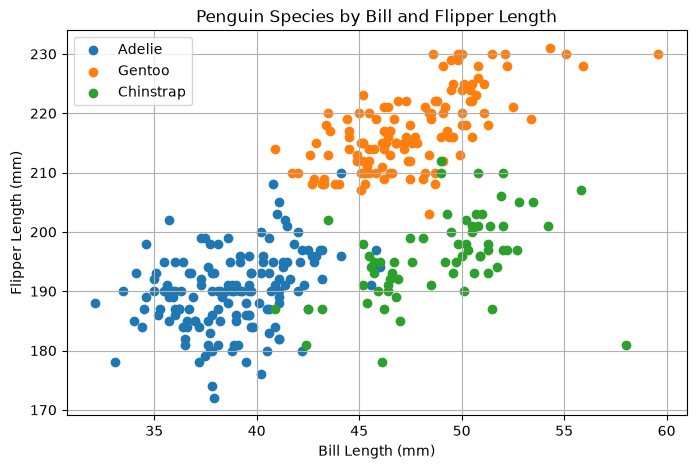

In [35]:
plt.figure(figsize=(8, 5))

for species in data["species"].unique():
    subset = data[data["species"] == species]

    plt.scatter(
        subset["bill_length_mm"],
        subset["flipper_length_mm"],
        label=species
    )

plt.xlabel("Bill Length (mm)")
plt.ylabel("Flipper Length (mm)")
plt.title("Penguin Species by Bill and Flipper Length")
plt.legend()
plt.grid(True)
plt.show()